# Preprocessing Technique 6: Dimensionality Reduction (PCA)
IT25102047 - Palihakkara P. J.
**Group:** 26-MTR-IT2011-04
**Dataset:** Breast Cancer Wisconsin (Original) - UCI Machine Learning Repository

## 1. What is this technique?
**Principal Component Analysis (PCA)** is an unsupervised dimensionality-reduction technique. It transforms a set of possibly-correlated features into a smaller set of **uncorrelated principal components**, ordered so that the first component captures the most variance in the data, the second captures the next most (orthogonal to the first), and so on.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
 import os
 os.chdir('/content/drive/MyDrive/Y2S1/AI_ML/Project/Progress Review/Group_26-MTR-IT2011-04/notebooks')

In [4]:
 print(os.getcwd())
 os.listdir('../data/raw')

/content/drive/MyDrive/Y2S1/AI_ML/Project/Progress Review/Group_26-MTR-IT2011-04/notebooks


['Index', 'breast-cancer-wisconsin.names', 'breast-cancer-wisconsin.data']

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 110

COLS = ['Sample_code_number','Clump_Thickness','Uniformity_of_Cell_Size','Uniformity_of_Cell_Shape',
        'Marginal_Adhesion','Single_Epithelial_Cell_Size','Bare_Nuclei','Bland_Chromatin',
        'Normal_Nucleoli','Mitoses','Class']

RAW_PATH = '../data/raw/breast-cancer-wisconsin.data'
VIZ_DIR = '../results/eda_visualizations'
os.makedirs(VIZ_DIR, exist_ok=True)

df = pd.read_csv(RAW_PATH, names=COLS)
print("Dataset shape:", df.shape)
df.head()


Dataset shape: (699, 11)


,Sample_code_number,Clump_Thickness,Uniformity_of_Cell_Size,Uniformity_of_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Class
0,1000025,5,1,1,1,2,1,3,1,1,2
1,1002945,5,4,4,5,7,10,3,2,1,2
2,1015425,3,1,1,1,2,2,3,1,1,2
3,1016277,6,8,8,1,3,4,3,7,1,2
4,1017023,4,1,1,3,2,1,3,1,1,2


In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df_p = df.copy()
df_p['Bare_Nuclei'] = df_p['Bare_Nuclei'].replace('?', np.nan).astype(float)
df_p['Bare_Nuclei'] = df_p['Bare_Nuclei'].fillna(df_p['Bare_Nuclei'].median())
feature_cols = ['Clump_Thickness','Uniformity_of_Cell_Size','Uniformity_of_Cell_Shape',
                'Marginal_Adhesion','Single_Epithelial_Cell_Size','Bare_Nuclei',
                'Bland_Chromatin','Normal_Nucleoli','Mitoses']
df_p[feature_cols] = df_p[feature_cols].astype(float)
df_p['Class_bin'] = df_p['Class'].map({2: 0, 4: 1})
df_p.head()

,Sample_code_number,Clump_Thickness,Uniformity_of_Cell_Size,Uniformity_of_Cell_Shape,Marginal_Adhesion,Single_Epithelial_Cell_Size,Bare_Nuclei,Bland_Chromatin,Normal_Nucleoli,Mitoses,Class,Class_bin
0,1000025,5.0,1.0,1.0,1.0,2.0,1.0,3.0,1.0,1.0,2,0
1,1002945,5.0,4.0,4.0,5.0,7.0,10.0,3.0,2.0,1.0,2,0
2,1015425,3.0,1.0,1.0,1.0,2.0,2.0,3.0,1.0,1.0,2,0
3,1016277,6.0,8.0,8.0,1.0,3.0,4.0,3.0,7.0,1.0,2,0
4,1017023,4.0,1.0,1.0,3.0,2.0,1.0,3.0,1.0,1.0,2,0


## 2. Why This Technique Was Needed
Our teammate's feature-selection analysis found that several features - most notably **Uniformity_of_Cell_Size** and **Uniformity_of_Cell_Shape** (r=0.91) - are **highly correlated with each other**, and in fact *every* feature pair in this dataset correlates positively (all above 0.34). This redundancy means the 9 raw features contain fewer than 9 truly *independent* signals. PCA lets us:
1. **Quantify** exactly how much of the dataset's variance is genuinely independent information.
2. **Visualize** the 9-dimensional feature space in 2D to sanity-check whether benign and malignant cases are separable at all - a useful sanity check before committing to Step 3 modelling.

In [7]:
X = df_p[feature_cols].values
X_scaled = StandardScaler().fit_transform(X)  # PCA requires standardized input

pca = PCA(n_components=9, random_state=42)
principal_components = pca.fit_transform(X_scaled)

var_ratio = pca.explained_variance_ratio_ * 100
cum_var = np.cumsum(var_ratio)

for i, (v, c) in enumerate(zip(var_ratio, cum_var), start=1):
    print(f"PC{i}: {v:5.2f}% of variance   (cumulative: {c:5.2f}%)")

n_for_90 = np.argmax(cum_var >= 90) + 1
n_for_95 = np.argmax(cum_var >= 95) + 1
print(f"\nComponents needed for >=90% variance: {n_for_90} (out of 9)")
print(f"Components needed for >=95% variance: {n_for_95} (out of 9)")

PC1: 65.45% of variance   (cumulative: 65.45%)
PC2:  8.61% of variance   (cumulative: 74.05%)
PC3:  5.99% of variance   (cumulative: 80.04%)
PC4:  5.17% of variance   (cumulative: 85.22%)
PC5:  4.23% of variance   (cumulative: 89.44%)
PC6:  3.37% of variance   (cumulative: 92.82%)
PC7:  3.29% of variance   (cumulative: 96.10%)
PC8:  2.91% of variance   (cumulative: 99.01%)
PC9:  0.99% of variance   (cumulative: 100.00%)

Components needed for >=90% variance: 6 (out of 9)
Components needed for >=95% variance: 7 (out of 9)


**Finding:** **PC1 alone explains 65.45%** of all variance in the data - a striking result that confirms just how correlated the 9 features are (a single underlying "severity" signal drives most of them together). PC1+PC2 together capture **74.05%**. However, reaching 95% of total variance still needs **7 of the 9 components** - so PCA offers only a **modest reduction in true dimensionality** here, not a dramatic one. We therefore use PCA primarily as an **exploratory/visualization tool** (2 components, for plotting) rather than as a hard feature-count reduction before modelling, where we will keep the original 9 interpretable clinical features per the "clinically interpretable" justification from our Dataset Justification slide.

## 3. EDA Visualization & Interpretation

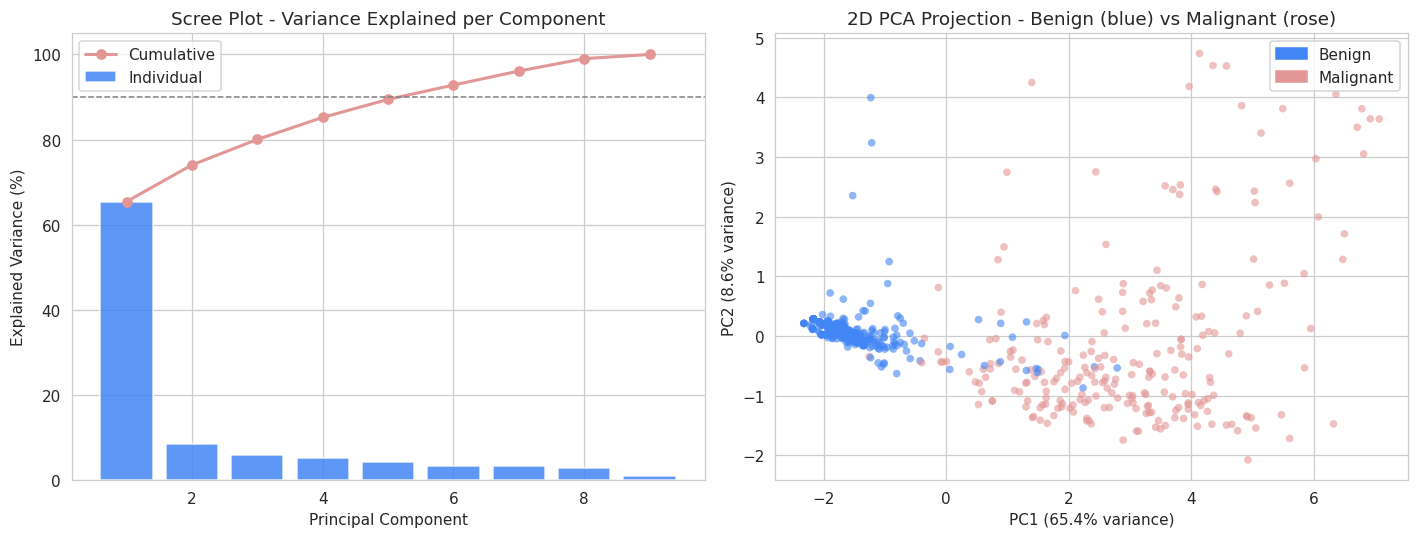

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Scree plot
axes[0].bar(range(1, 10), var_ratio, color='#4285F4', alpha=0.85, label='Individual')
axes[0].plot(range(1, 10), cum_var, color='#E39696', marker='o', linewidth=2, label='Cumulative')
axes[0].axhline(90, color='gray', linestyle='--', linewidth=1)
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Explained Variance (%)')
axes[0].set_title('Scree Plot - Variance Explained per Component')
axes[0].legend()

# 2D PCA scatter colored by class
colors = df_p['Class_bin'].map({0: '#4285F4', 1: '#E39696'})
axes[1].scatter(principal_components[:, 0], principal_components[:, 1],
                 c=colors, alpha=0.6, edgecolor='none', s=25)
axes[1].set_xlabel(f'PC1 ({var_ratio[0]:.1f}% variance)')
axes[1].set_ylabel(f'PC2 ({var_ratio[1]:.1f}% variance)')
axes[1].set_title('2D PCA Projection - Benign (blue) vs Malignant (rose)')
from matplotlib.patches import Patch
axes[1].legend(handles=[Patch(color='#4285F4', label='Benign'), Patch(color='#E39696', label='Malignant')])

plt.tight_layout()
plt.savefig(f'{VIZ_DIR}/06_pca_scree_and_scatter.png', bbox_inches='tight')
plt.show()

**Interpretation:** The scree plot's steep drop after PC1 visually confirms the heavy redundancy identified via correlation analysis. More importantly, the 2D scatter plot shows benign (blue) and malignant (rose) cases form **two largely separable clusters** using just the first two components - strong early evidence that a supervised classifier should be able to learn a clean decision boundary in Step 3, even before any model has been trained.

## 4. Summary
| Item | Result |
|---|---|
| Technique | PCA (dimensionality reduction / visualization) |
| Input | 9 standardized features |
| PC1 variance explained | 65.45% |
| PC1+PC2 variance explained | 74.05% |
| Components needed for 95% variance | 7 of 9 (modest true reduction) |
| Key visual finding | Benign vs malignant classes are largely separable even in 2D |
| Modelling decision | Keep all 9 original interpretable features for Step 3; use PCA for visualization/EDA only |